This notebook builds a pointwise learning-to-rank dataset and trains ML models
to predict whether a dealer will view a given item in the future.(Generally)

# Imports and config

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.csv as pacsv
import pyarrow as pa
from pathlib import Path
from datetime import timedelta
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

HORIZON_DAYS = 7
TOP_N_GLOBAL = 100

VIEW_FOLDER = Path("l2r_dataset/views")
BID_FOLDER = Path("l2r_dataset/bids")


# Load data

In [2]:
def read_folder_csvs(folder):
    tables = [pacsv.read_csv(file) for file in sorted(folder.glob("*.csv"))]
    return pa.concat_tables(tables).to_pandas()

view_df = read_folder_csvs(VIEW_FOLDER)
bid_df = read_folder_csvs(BID_FOLDER)

model_df = pd.read_csv("brand_model_english_persian_ids.csv")

view_df.rename(columns={"created_time": "event_time"}, inplace=True)
bid_df.rename(columns={"created_time": "event_time"}, inplace=True)

# Basic cleaning

In [3]:
view_df["event_time"] = pd.to_datetime(view_df["event_time"], utc=True).dt.floor("min")
bid_df["event_time"] = pd.to_datetime(bid_df["event_time"], utc=True).dt.floor("min")

view_df["item_id"] = view_df["brand_id"].astype(str) + "_" + view_df["model_id"].astype(str)
bid_df["item_id"] = bid_df["brand_id"].astype(str) + "_" + bid_df["model_id"].astype(str)


In [4]:
view_df.head()

,view_id,dealer_id,auction_id,brand_id,model_id,event_time,item_id
0,45651932,396166,387349,100,599,2026-07-02 13:15:00+00:00,100_599
1,45651948,330121,387349,100,599,2026-07-02 13:15:00+00:00,100_599
2,45652045,298137,387349,100,599,2026-07-02 13:15:00+00:00,100_599
3,45652046,331117,387349,100,599,2026-07-02 13:15:00+00:00,100_599
4,45652060,298137,387349,100,599,2026-07-02 13:20:00+00:00,100_599


# Dedup data and count redundant data in minute

In [5]:
def dedup_with_count(df, count_col):
    df = df.copy()
    df["event_time"] = pd.to_datetime(df["event_time"], errors="coerce")

    subset_cols = ["dealer_id", "brand_id", "model_id", "event_time", "auction_id"]

    df[count_col] = (
        df.groupby(subset_cols)["dealer_id"]
          .transform("size")
    )

    df = df.drop_duplicates(subset=subset_cols, keep="first")

    return df

In [6]:
print("view table size before: ", len(view_df))
print("bid table size before: ", len(bid_df))
print("*******")

view_df = dedup_with_count(view_df, "view_in_minute")
bid_df  = dedup_with_count(bid_df, "bid_in_minute")

print("view table size after: ", len(view_df))
print("bid table size after: ", len(bid_df))

view table size before:  12139008
bid table size before:  1139590
*******
view table size after:  3129885
bid table size after:  994950


## Sort data by time
Time sorting helps later when we build history-based features and avoid leakage.

In [7]:
view_df = view_df.sort_values("event_time").reset_index(drop=True)
bid_df = bid_df.sort_values("event_time").reset_index(drop=True)

## Build global popularity and dealer history

These objects are used to construct a practical candidate set:
dealer-touched items plus globally popular items.


In [8]:
def global_popular(view_df, cutoff_time):
    past_views = view_df[view_df["event_time"] < cutoff_time]
    global_popular_items = (
        past_views.groupby("item_id")
        .size()
        .sort_values(ascending=False)
        .head(TOP_N_GLOBAL)
        .index
        .tolist()
        )
    return global_popular_items

def dealer_touched(view_df, cutoff_time):
    past_views = view_df[view_df["event_time"] < cutoff_time]
    dealer_touched_items = (
            past_views.groupby("dealer_id")["item_id"]
            .apply(set)
            .to_dict()
        )
    return dealer_touched_items

def build_candidates(dealer_touched_items, top_global):
    candidates = []
    for d_id, items in dealer_touched_items.items():
        top_k_global = top_global

        # Top k based on touched item per dealer
        if len(items) < 10:
            top_k_global = top_global[:TOP_N_GLOBAL//10]
        elif len(items) < 20:
            top_k_global = top_global[:TOP_N_GLOBAL//5]
        elif len(items) < 30:
            top_k_global = top_global[:TOP_N_GLOBAL//2]
        
        combined = items.union(set(top_k_global)) 
        for i_id in combined:
            candidates.append({"dealer_id": d_id, "item_id": i_id})
    return candidates


## Define the target label

In [9]:
def build_future_labels(view_df, cutoff_time, horizon_days=HORIZON_DAYS):
    future_end = cutoff_time + timedelta(days=horizon_days)

    future_views = view_df[
        (view_df["event_time"] >= cutoff_time) &
        (view_df["event_time"] < future_end)
    ]

    labels = (
        future_views[["dealer_id", "item_id"]]
        .drop_duplicates()
        .assign(label=1)
    )

    return labels


## Feature engineering helpers

All features must use only events strictly before the cutoff time.


In [10]:
def get_history_features(df, prefix, cutoff_time):
    # Only look at events before cutoff
    past = df[df["event_time"] < cutoff_time].copy()
    
    # 1. Dealer-Item Recency
    last_event = past.groupby(["dealer_id", "item_id"])["event_time"].max().reset_index()
    last_event[f"days_since_last_{prefix}"] = (cutoff_time - last_event["event_time"]).dt.total_seconds() / 86400
    
    # 2. Dealer-Item Counts in windows
    features = last_event[["dealer_id", "item_id", f"days_since_last_{prefix}"]].copy()
    
    for days in [3, 7, 14]:
        start_date = cutoff_time - timedelta(days=days)
        window_counts = past[past["event_time"] >= start_date].groupby(["dealer_id", "item_id"])[f"{prefix}_in_minute"].sum().reset_index(name=f"{prefix}s_{days}d")
        features = features.merge(window_counts, on=["dealer_id", "item_id"], how="left")
    
    # 3. no-overlap 
    count_cols = [f"{prefix}s_3d", f"{prefix}s_7d", f"{prefix}s_14d"]
    features[count_cols] = features[count_cols].fillna(0)

    
    features[f"{prefix}s_14d"] = features[f"{prefix}s_14d"] - features[f"{prefix}s_7d"]  
    features[f"{prefix}s_7d"]  = features[f"{prefix}s_7d"]  - features[f"{prefix}s_3d"]  
        
    # 4. Global Item and Dealer Item(**) Totals
    dealer_item_totals = past.groupby(["dealer_id", "item_id"])[f"{prefix}_in_minute"].sum().reset_index(name=f"dealer_item_total_{prefix}s")
    item_totals = past.groupby("item_id").size().reset_index(name=f"item_global_{prefix}s")
    
    return features, dealer_item_totals, item_totals


## Build the pointwise dataset

We iterate over cutoffs, then over dealers, then over the candidate items
for each dealer. Labels come from the future window.

In [11]:
def build_fast_pointwise_dataset(view_df, bid_df, cutoffs, horizon_days=HORIZON_DAYS):
    all_chunks = []
    
    for cutoff in cutoffs:
        print(f"Processing cutoff: {cutoff}...")
        
        # A. Build Candidate Set for this cutoff
        # (Dealer-touched items before cutoff + Global Top N)

        dealer_touched_items = dealer_touched(view_df, cutoff)
        top_global = global_popular(view_df, cutoff)

        # build candidates
        candidates = build_candidates(dealer_touched_items, top_global)
        
        chunk = pd.DataFrame(candidates)
        
        # B. Get View Features
        v_feat, d_i_v_tot, i_v_tot = get_history_features(view_df, "view", cutoff)
        
        # C. Get Bid Features
        b_feat, d_i_b_tot, i_b_tot = get_history_features(bid_df, "bid", cutoff)
        
        # D. Merge everything onto candidates
        chunk = chunk.merge(v_feat, on=["dealer_id", "item_id"], how="left")
        chunk = chunk.merge(b_feat, on=["dealer_id", "item_id"], how="left")

        chunk = chunk.merge(d_i_v_tot, on=["dealer_id", "item_id"], how="left")
        chunk = chunk.merge(d_i_b_tot, on=["dealer_id", "item_id"], how="left")
        chunk["dealer_item_total_views"] = chunk["dealer_item_total_views"].fillna(0)
        chunk["dealer_item_total_bids"] = chunk["dealer_item_total_bids"].fillna(0)
        chunk["bid_view_ratio"] = (
            chunk["dealer_item_total_bids"] / chunk["dealer_item_total_views"].replace(0, np.nan)
        ).fillna(0)
        
        chunk = chunk.merge(i_v_tot, on="item_id", how="left")
        chunk = chunk.merge(i_b_tot, on="item_id", how="left")
        chunk["global_bid_view_ratio"] = (
                    chunk["item_global_bids"] / chunk["item_global_views"].replace(0, np.nan)
                ).fillna(0)

        chunk.drop(columns=["dealer_item_total_views", "dealer_item_total_bids", "item_global_views", "item_global_bids"], inplace=True)
        
        # E. Add Labels (Future window)
        labels = build_future_labels(view_df, cutoff, horizon_days)
        chunk = chunk.merge(labels, on=["dealer_id", "item_id"], how="left")
        chunk["label"] = chunk["label"].fillna(0).astype(int)
        
        all_chunks.append(chunk)
        
    return pd.concat(all_chunks, ignore_index=True)

## Choose cutoffs

We pick several cutoffs in the valid time range.
The last `HORIZON_DAYS` are reserved for the label window.


In [12]:
# Use the same cutoffs logic from before
min_time = view_df["event_time"].min()
max_time = view_df["event_time"].max()
valid_max_cutoff = max_time - timedelta(days=HORIZON_DAYS)

# 1 cutoffs to have enough data
cutoffs = pd.date_range(
    start=valid_max_cutoff, 
    end=valid_max_cutoff, 
    periods=1
)

cutoffs

DatetimeIndex(['2026-08-10 15:25:00+00:00'], dtype='datetime64[ns, UTC]', freq=None)

## Generate the training table

This may take some time depending on dataset size.


In [13]:
pointwise_df = build_fast_pointwise_dataset(view_df, bid_df, cutoffs)

print("\nFinal shape:", pointwise_df.shape)
display(pointwise_df.head(100))


Processing cutoff: 2026-08-10 15:25:00+00:00...

Final shape: (623990, 13)


,dealer_id,item_id,days_since_last_view,views_3d,views_7d,views_14d,days_since_last_bid,bids_3d,bids_7d,bids_14d,bid_view_ratio,global_bid_view_ratio,label
0,3,100_597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.276350,0
1,3,136_682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.273755,0
2,3,132_856,18.954861,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.321038,0
3,3,138_513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.341403,0
4,3,100_503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.221955,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,23,137_805,5.173611,0.0,2.0,0.0,NaN,NaN,NaN,NaN,0.0,0.448183,0
96,23,109_646,10.243056,0.0,0.0,1.0,NaN,NaN,NaN,NaN,0.0,0.239991,0
97,23,187_1121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.515027,0
98,23,193_1165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.462303,0


# Show Dealer 82

In [14]:
pointwise_df[pointwise_df['dealer_id'] == 82].head(100)

,dealer_id,item_id,days_since_last_view,views_3d,views_7d,views_14d,days_since_last_bid,bids_3d,bids_7d,bids_14d,bid_view_ratio,global_bid_view_ratio,label
258,82,102_1325,0.121528,1.0,0.0,0.0,0.106944,10.0,0.0,0.0,10.000000,0.229167,0
259,82,102_1309,32.263889,0.0,0.0,0.0,32.266667,0.0,0.0,0.0,0.666667,0.243697,0
260,82,204_1275,0.083333,2.0,0.0,0.0,0.085417,2.0,0.0,0.0,0.714286,0.443089,0
261,82,114_692,0.281250,6.0,4.0,22.0,0.282639,12.0,8.0,61.0,2.028169,0.459056,1
262,82,139_884,0.013889,6.0,2.0,11.0,0.014583,4.0,2.0,10.0,0.930693,0.297776,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
353,82,103_988,0.027778,54.0,77.0,225.0,0.016667,149.0,233.0,619.0,2.922162,0.559598,1
354,82,132_844,0.218750,3.0,2.0,2.0,0.219444,3.0,2.0,2.0,0.941176,0.490083,1
355,82,187_1106,0.118056,18.0,13.0,41.0,0.119444,16.0,13.0,37.0,1.131980,0.525697,1
356,82,171_1147,0.090278,10.0,7.0,23.0,0.081944,15.0,7.0,71.0,2.565217,0.619621,1


## Imputation and Feature Prep

Fill missing values (NAs in counts = 0, NAs in recency = 999).


In [15]:
# Impute counts with 0
count_cols = [c for c in pointwise_df.columns if "s_" in c]
pointwise_df[count_cols] = pointwise_df[count_cols].fillna(0)

ratio_cols = [c for c in pointwise_df.columns if "ratio" in c]
pointwise_df[ratio_cols] = pointwise_df[ratio_cols].fillna(0)

# Impute recency with 999
recency_cols = [c for c in pointwise_df.columns if "days_since_last" in c]
pointwise_df[recency_cols] = pointwise_df[recency_cols].fillna(999.0)

FEATURE_COLUMNS = ['dealer_id', 'brand_id', 'model_id'] + recency_cols + ratio_cols + count_cols 
TARGET_COLUMN = "label"

# Clean the duplicates and keep order
seen = set()
FEATURE_COLUMNS = [f for f in FEATURE_COLUMNS if not (f in seen or seen.add(f))]

pointwise_df[['brand_id', 'model_id']] = pointwise_df['item_id'].str.split('_', expand=True)
pointwise_df['brand_id'] = pointwise_df['brand_id'].astype(int)
pointwise_df['model_id'] = pointwise_df['model_id'].astype(int)

X = pointwise_df[FEATURE_COLUMNS]
y = pointwise_df[TARGET_COLUMN]

print("Features:",FEATURE_COLUMNS)
print("Positive rate:", y.mean())


Features: ['dealer_id', 'brand_id', 'model_id', 'days_since_last_view', 'days_since_last_bid', 'bid_view_ratio', 'global_bid_view_ratio', 'views_3d', 'views_7d', 'views_14d', 'bids_3d', 'bids_7d', 'bids_14d']
Positive rate: 0.13478901905479254


# Correlation check

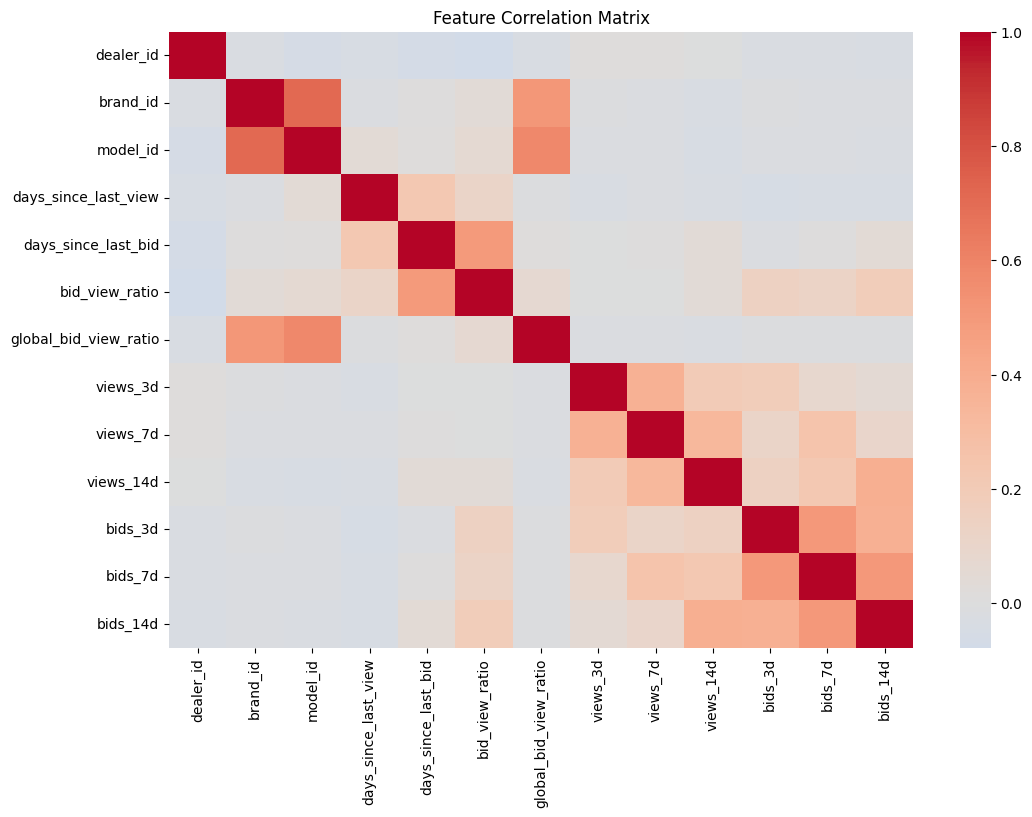

In [16]:
corr_df = pointwise_df[FEATURE_COLUMNS].corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr_df, cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix")
plt.show()


In [17]:
corr_abs = corr_df.abs()

high_corr_pairs = []
cols = corr_abs.columns.tolist()

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        if corr_abs.iloc[i, j] >= 0.80:
            high_corr_pairs.append((cols[i], cols[j], corr_abs.iloc[i, j]))

high_corr_pairs


[]

In [18]:
DROP_FEATURES_B1 = [
]

target_col = TARGET_COLUMN
selected_features_b1 = [
    feature
    for feature in FEATURE_COLUMNS
    if feature not in DROP_FEATURES_B1
]

print("Dropped features:", DROP_FEATURES_B1)
print("Selected features for B1:")
print(selected_features_b1)


Dropped features: []
Selected features for B1:
['dealer_id', 'brand_id', 'model_id', 'days_since_last_view', 'days_since_last_bid', 'bid_view_ratio', 'global_bid_view_ratio', 'views_3d', 'views_7d', 'views_14d', 'bids_3d', 'bids_7d', 'bids_14d']


# Split dataset

In [19]:
# Split the 1 cutoffs: all for train data
train_df = pointwise_df.copy()

print("\n--- Split by cutoffs ---")
print("Cutoffs:", list(cutoffs.astype(str)))

print("\nPositive rates:")
print("Train:", train_df[target_col].mean())




--- Split by cutoffs ---
Cutoffs: ['2026-08-10 15:25:00+00:00']

Positive rates:
Train: 0.13478901905479254


In [20]:
# Build feature matrices and target vectors
X_train_b1 = train_df[selected_features_b1].copy()
y_train_b1 = train_df[target_col].astype(int).to_numpy()

X_test_b1 = train_df[selected_features_b1].copy()
y_test_b1 = train_df[target_col].astype(int).to_numpy()

print("B1 input shapes:")
print(f"Train: X={X_train_b1.shape}, positive labels={y_train_b1.sum():,}")
print(f"Test:  X={X_test_b1.shape}, positive labels={y_test_b1.sum():,}")


B1 input shapes:
Train: X=(623990, 13), positive labels=84,107
Test:  X=(623990, 13), positive labels=84,107


# Traning B1 model

In [21]:
# Define the B1 pointwise model
b1_model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                C=1.0,
                solver="lbfgs",
                random_state=42,
            ),
        ),
    ]
)

# Train the model only on the training split
b1_model.fit(X_train_b1, y_train_b1)

# Generate ranking scores for test sets
test_scores_b1 = b1_model.predict_proba(X_test_b1)[:, 1]

print("B1 model training completed.")


B1 model training completed.


In [22]:
from sklearn.metrics import average_precision_score, roc_auc_score

test_roc_auc_b1 = roc_auc_score(y_test_b1, test_scores_b1)
test_pr_auc_b1 = average_precision_score(y_test_b1, test_scores_b1)

print("--- B1 Classification Metrics ---")
print(
    f"Test       | "
    f"ROC-AUC: {test_roc_auc_b1:.4f} | "
    f"PR-AUC: {test_pr_auc_b1:.4f}"
)


--- B1 Classification Metrics ---
Test       | ROC-AUC: 0.7250 | PR-AUC: 0.3983


In [23]:
lr_b1 = b1_model.named_steps["classifier"]

feature_importance_b1 = (
    pd.DataFrame(
        {
            "feature": selected_features_b1,
            "coefficient": lr_b1.coef_[0],
            "abs_coefficient": np.abs(lr_b1.coef_[0]),
        }
    )
    .sort_values("abs_coefficient", ascending=False)
    .reset_index(drop=True)
)

print("--- B1 Feature Importance ---")
display(feature_importance_b1)


--- B1 Feature Importance ---


,feature,coefficient,abs_coefficient
0,views_14d,1.248038,1.248038
1,bids_3d,0.928187,0.928187
2,views_3d,0.488779,0.488779
3,bids_7d,0.385480,0.385480
4,days_since_last_bid,0.320181,0.320181
5,model_id,-0.264406,0.264406
6,views_7d,0.196331,0.196331
7,dealer_id,-0.160228,0.160228
8,days_since_last_view,-0.099689,0.099689
9,bids_14d,0.091395,0.091395


# Training B2 model

In [25]:
from catboost import CatBoostClassifier, Pool

# Define categorical features for CatBoost optimization
cat_features = ['dealer_id', 'brand_id', 'model_id']

# Prepare the data in CatBoost Pool format
X_train_b2 = train_df[FEATURE_COLUMNS].copy()
y_train_b2 = train_df[target_col].astype(int).to_numpy()

train_pool = Pool(data=X_train_b2, label=y_train_b2, cat_features=cat_features)

# Configure the CatBoost model
# auto_class_weights="Balanced" handles the class imbalance for sales prediction
model_b2 = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    auto_class_weights="Balanced",
    random_state=42,
    verbose=100  # Log output every 100 iterations
)

# Train the model on the full training set
model_b2.fit(train_pool)

0:	learn: 0.6676096	total: 984ms	remaining: 16m 22s
100:	learn: 0.4148046	total: 58.6s	remaining: 8m 41s
200:	learn: 0.4094902	total: 1m 55s	remaining: 7m 39s
300:	learn: 0.4059622	total: 2m 53s	remaining: 6m 43s
400:	learn: 0.4028848	total: 3m 55s	remaining: 5m 51s
500:	learn: 0.4006302	total: 4m 56s	remaining: 4m 54s
600:	learn: 0.3988156	total: 5m 56s	remaining: 3m 56s
700:	learn: 0.3970999	total: 7m	remaining: 2m 59s
800:	learn: 0.3957303	total: 8m 3s	remaining: 2m
900:	learn: 0.3946299	total: 9m 6s	remaining: 1m
999:	learn: 0.3937272	total: 10m 8s	remaining: 0us


CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=1000, learning_rate=0.05, random_state=42, verbose=100)

In [26]:
# Predict probabilities for the test set
test_preds = model_b2.predict_proba(X_train_b2)[:, 1]
#
print("--- B2 Classification Metrics ---")
print(f"ROC-AUC: {roc_auc_score(y_train_b2, test_preds):.4f}")
print(f"PR-AUC: {average_precision_score(y_train_b2,  test_preds):.4f}")

--- B2 Classification Metrics ---
ROC-AUC: 0.9433
PR-AUC: 0.7719


# Recall & NDCG on B1 and B2

In [27]:
from sklearn.metrics import ndcg_score

def evaluate_ranking(df, k=10):
    """
    df: DataFrame containing 'dealer_id', 'y_true', 'y_score'
    k: The number of top items to consider
    """
    recalls = []
    ndcgs = []
    
    # Group by dealer to evaluate ranking per dealer
    for dealer_id, group in df.groupby('dealer_id'):
        # Sort items by model predicted score in descending order
        group = group.sort_values(by='y_score', ascending=False)
        
        # Get actual and predicted labels
        y_true = group['y_true'].values
        y_score = group['y_score'].values

        if np.sum(y_true) == 0:
                    continue
        
        # Recall@K: Proportion of relevant items found in top K
        recall = np.sum(y_true[:k]) / np.sum(y_true)
        recalls.append(recall)
        
        # NDCG@K: Ranking quality
        # ndcg_score expects (n_samples, n_classes) but for binary ranking we can use it like this
        ndcg = ndcg_score([y_true], [y_score], k=k)
        ndcgs.append(ndcg)
            
    return np.mean(recalls), np.mean(ndcgs)


#B1
test_df_B1 = train_df.copy()
test_df_B1['y_score'] = test_scores_b1
test_df_B1['y_true'] = y_test_b1

recall_at_10_B1, ndcg_at_10_B1 = evaluate_ranking(test_df_B1, k=10)
recall_at_5_B1, ndcg_at_5_B1 = evaluate_ranking(test_df_B1, k=5)

#B2
test_df_B2 = train_df.copy()
test_df_B2['y_score'] = test_preds
test_df_B2['y_true'] = y_train_b2

recall_at_10_B2, ndcg_at_10_B2 = evaluate_ranking(test_df_B2, k=10)
recall_at_5_B2, ndcg_at_5_B2 = evaluate_ranking(test_df_B2, k=5)

In [28]:
results_data = {
    'Model': ['B1 (Logistic)', 'B2 (CatBoost)'],
    'Recall@5': [recall_at_5_B1, recall_at_5_B2],
    'NDCG@5': [ndcg_at_5_B1, ndcg_at_5_B2],
    'Recall@10': [recall_at_10_B1, recall_at_10_B2],
    'NDCG@10': [ndcg_at_10_B1, ndcg_at_10_B2]
}

results_df = pd.DataFrame(results_data)

results_df.set_index('Model', inplace=True)

print(results_df)

               Recall@5    NDCG@5  Recall@10   NDCG@10
Model                                                 
B1 (Logistic)  0.248019  0.557567   0.423842  0.562979
B2 (CatBoost)  0.426221  0.783974   0.598640  0.780614
